# Model 2.2: Predicting goals scored by a team
**HIT140 Assessment 3 (revised scope)**
Marium Akter Mim, S397784

Goal: predict how many goals one team scores in a FIFA World Cup 2026 match, using 8 variables that are known before the match.

Data file: `marium_model22_data.csv` (208 rows, one row for each team in each match).

My plan:
1. Load and check the data
2. Look at the data (goals, correlations, VIF)
3. My idea: the model does not know who the team plays against, so I add the opponent's FIFA ranking
4. Compare **Model A (group)**, the group's original Model 2.2, with **Model B (Marium)**, my improved version
5. Check the results with a baseline, a test set and cross validation
6. Charts and summary

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

os.makedirs("charts", exist_ok=True)

## 1. Load and check the data

In [2]:
df = pd.read_csv("marium_model22_data.csv")
print("rows and columns:", df.shape)
df.head()

rows and columns: (208, 13)


,Match_Number,Date,Team,Opponent,Goals_Scored,Team_xG,Average_Goals_Scored,Average_Age,Transfers_2025,Coach_Salary_EUR,FIFA_Ranking_Apr2026,Forward_Goal_Rate,Squad_Goals
0,1,2026-06-11,Mexico,South Africa,2,1.05,1.6,27.90,178,2500000,15,0.206,127
1,1,2026-06-11,South Africa,Mexico,0,1.42,1.5,26.81,49,900000,60,0.202,68
2,2,2026-06-12,Korea Republic,Czechia,2,0.93,1.5,28.07,103,2160000,25,0.336,144
3,2,2026-06-12,Czechia,Korea Republic,1,0.77,2.2,27.62,100,180000,41,0.256,100
4,3,2026-06-12,Canada,Bosnia and Herzegovina,1,1.14,1.1,26.97,90,2500000,30,0.280,141


In [3]:
# any empty cells?
print("missing values:", df.isna().sum().sum())

# any row repeated?
print("duplicate rows:", df.duplicated().sum())

# every match should have exactly 2 rows (one for each team)
rows_per_match = df.groupby("Match_Number").size()
print("matches:", rows_per_match.shape[0])
print("all matches have 2 rows:", (rows_per_match == 2).all())

missing values: 0
duplicate rows: 0
matches: 104
all matches have 2 rows: True


In [4]:
# look for values that are not possible (nothing here should be below 0)
numbers = df.select_dtypes("number")
print((numbers < 0).sum()[lambda s: s > 0])
df[df["Team_xG"] < 0][["Match_Number", "Team", "Opponent", "Team_xG"]]

Team_xG    3
dtype: int64


,Match_Number,Team,Opponent,Team_xG
45,23,Panama,Ghana,-0.11
92,47,Panama,Croatia,-0.11
132,67,Panama,England,-0.11


In [5]:
# xG can not be negative, so -0.11 is a data error for Panama.
# I set it to 0, which is the closest possible value.
df["Team_xG"] = df["Team_xG"].clip(lower=0)
print("negative xG left:", (df["Team_xG"] < 0).sum())

negative xG left: 0


## 2. Look at the data

In [6]:
goals = df["Goals_Scored"]
print(goals.describe().round(2))
print()
print(goals.value_counts().sort_index())

count    208.00
mean       1.48
std        1.39
min        0.00
25%        0.00
50%        1.00
75%        2.00
max        7.00
Name: Goals_Scored, dtype: float64

Goals_Scored
0    55
1    71
2    39
3    25
4    10
5     5
6     2
7     1
Name: count, dtype: int64


In [7]:
original_vars = ["Team_xG", "Average_Goals_Scored", "Average_Age", "Transfers_2025",
                 "Coach_Salary_EUR", "FIFA_Ranking_Apr2026", "Forward_Goal_Rate", "Squad_Goals"]

# how strong is the link between each variable and goals?
corr_goals = df[original_vars].corrwith(goals).sort_values()
corr_goals.round(2)

FIFA_Ranking_Apr2026   -0.37
Average_Age            -0.10
Coach_Salary_EUR        0.26
Transfers_2025          0.27
Squad_Goals             0.29
Team_xG                 0.29
Average_Goals_Scored    0.30
Forward_Goal_Rate       0.35
dtype: float64

In [8]:
# variables that carry the same information
print("Team_xG vs Average_Goals_Scored:", round(df["Team_xG"].corr(df["Average_Goals_Scored"]), 2))
print("Transfers_2025 vs Coach_Salary_EUR:", round(df["Transfers_2025"].corr(df["Coach_Salary_EUR"]), 2))
print("Forward_Goal_Rate vs Squad_Goals:", round(df["Forward_Goal_Rate"].corr(df["Squad_Goals"]), 2))

Team_xG vs Average_Goals_Scored: 0.64
Transfers_2025 vs Coach_Salary_EUR: 0.78
Forward_Goal_Rate vs Squad_Goals: 0.67


In [9]:
def vif_table(data, cols):
    X = sm.add_constant(data[cols])
    rows = []
    for i, c in enumerate(cols):
        rows.append([c, round(variance_inflation_factor(X.values, i + 1), 2)])
    return pd.DataFrame(rows, columns=["Variable", "VIF"])

vif_table(df, original_vars)

,Variable,VIF
0,Team_xG,2.35
1,Average_Goals_Scored,2.20
2,Average_Age,1.25
3,Transfers_2025,3.57
4,Coach_Salary_EUR,2.96
5,FIFA_Ranking_Apr2026,2.58
6,Forward_Goal_Rate,2.30
7,Squad_Goals,2.55


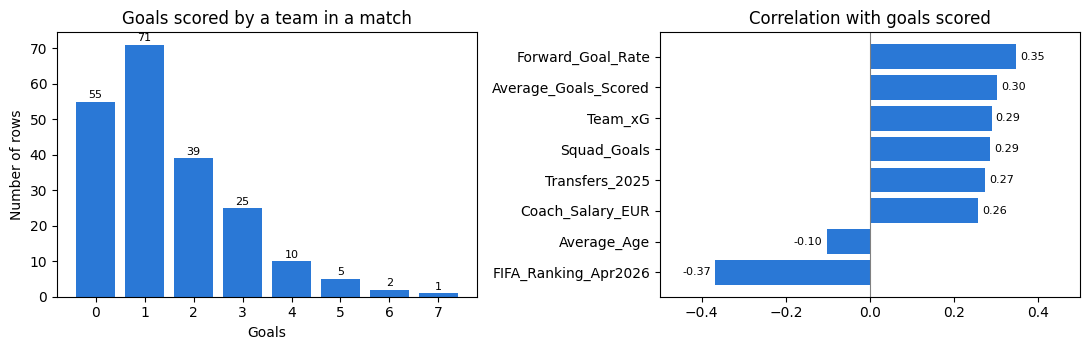

In [10]:
# chart 1: goals per team and correlation with goals
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

counts = goals.value_counts().sort_index()
ax[0].bar(counts.index, counts.values, color="#2a78d6")
for x, v in counts.items():
    ax[0].text(x, v + 1, str(v), ha="center", fontsize=8)
ax[0].set_title("Goals scored by a team in a match")
ax[0].set_xlabel("Goals")
ax[0].set_ylabel("Number of rows")

ax[1].barh(corr_goals.index, corr_goals.values, color="#2a78d6")
ax[1].axvline(0, color="grey", linewidth=0.8)
for i, v in enumerate(corr_goals.values):
    ax[1].text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center",
               ha="left" if v >= 0 else "right", fontsize=8)
ax[1].set_xlim(-0.5, 0.5)
ax[1].set_title("Correlation with goals scored")

plt.tight_layout()
plt.savefig("charts/chart1_goals_and_correlation.png", dpi=200)
plt.show()

## 3. My idea: add the opponent

All 8 original variables describe only the team itself. So the model gives a team the same prediction in every match, whether it plays Spain or a small team. That does not make sense for football.

The data already has every team's FIFA ranking, so I can look up the **opponent's ranking** for each row. It is known before the match, so it follows the rule.

To keep exactly 8 variables, I take out **Team_xG**, because:
* it repeats Average_Goals_Scored (correlation 0.64)
* it had invalid values (Panama)

In [11]:
# make a small table with each team's ranking, then match it to the opponent
rank_table = df[["Match_Number", "Team", "FIFA_Ranking_Apr2026"]].rename(
    columns={"Team": "Opponent", "FIFA_Ranking_Apr2026": "Opponent_FIFA_Ranking"})

df = df.merge(rank_table, on=["Match_Number", "Opponent"], how="left")
print("missing opponent ranking:", df["Opponent_FIFA_Ranking"].isna().sum())
df[["Team", "Opponent", "FIFA_Ranking_Apr2026", "Opponent_FIFA_Ranking", "Goals_Scored"]].head(6)

missing opponent ranking: 0


,Team,Opponent,FIFA_Ranking_Apr2026,Opponent_FIFA_Ranking,Goals_Scored
0,Mexico,South Africa,15,60,2
1,South Africa,Mexico,60,15,0
2,Korea Republic,Czechia,25,41,2
3,Czechia,Korea Republic,41,25,1
4,Canada,Bosnia and Herzegovina,30,65,1
5,Bosnia and Herzegovina,Canada,65,30,1


In [12]:
# a higher rank number means a weaker opponent, so we expect more goals
print("Opponent_FIFA_Ranking vs goals:", round(df["Opponent_FIFA_Ranking"].corr(goals), 2))

Opponent_FIFA_Ranking vs goals: 0.34


In [13]:
my_vars = ["Opponent_FIFA_Ranking", "Average_Goals_Scored", "Average_Age", "Transfers_2025",
           "Coach_Salary_EUR", "FIFA_Ranking_Apr2026", "Forward_Goal_Rate", "Squad_Goals"]
print("number of variables:", len(my_vars))
vif_table(df, my_vars)

number of variables: 8


,Variable,VIF
0,Opponent_FIFA_Ranking,1.02
1,Average_Goals_Scored,2.03
2,Average_Age,1.20
3,Transfers_2025,3.35
4,Coach_Salary_EUR,2.74
5,FIFA_Ranking_Apr2026,2.35
6,Forward_Goal_Rate,2.30
7,Squad_Goals,2.47


## 4. Train and test

I keep both teams of the same match together, so a match is never in training and testing at the same time. 80% of matches are for training and 20% for testing.

### The two models

| | Model A (group) | Model B (Marium) |
|---|---|---|
| What it is | the group's original Model 2.2 | my improved version |
| Change | none | Team_xG replaced by Opponent_FIFA_Ranking |
| Number of variables | 8 | 8 |

Both models use the same rows, the same split and the same measures, so the comparison is fair.

In [14]:
# the variables of both models side by side
pd.DataFrame({"Model A (group)": original_vars, "Model B (Marium)": my_vars})

,Model A (group),Model B (Marium)
0,Team_xG,Opponent_FIFA_Ranking
1,Average_Goals_Scored,Average_Goals_Scored
2,Average_Age,Average_Age
3,Transfers_2025,Transfers_2025
4,Coach_Salary_EUR,Coach_Salary_EUR
5,FIFA_Ranking_Apr2026,FIFA_Ranking_Apr2026
6,Forward_Goal_Rate,Forward_Goal_Rate
7,Squad_Goals,Squad_Goals


In [15]:
y = df["Goals_Scored"]
match = df["Match_Number"]

split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=7)
train_rows, test_rows = next(split.split(df, y, groups=match))
print("training rows:", len(train_rows), " testing rows:", len(test_rows))
print("matches in both sets:", len(set(match.iloc[train_rows]) & set(match.iloc[test_rows])))

training rows: 166  testing rows: 42
matches in both sets: 0


In [16]:
def scores(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}

y_train, y_test = y.iloc[train_rows], y.iloc[test_rows]
results = {}

# baseline: always guess the average goals of the training set
results["Baseline (average)"] = scores(y_test, np.full(len(y_test), y_train.mean()))

# Model A (group): the group's original 8 variables
model_a = LinearRegression().fit(df[original_vars].iloc[train_rows], y_train)
pred_a = model_a.predict(df[original_vars].iloc[test_rows])
results["Model A (group)"] = scores(y_test, pred_a)

# Model B (Marium): my 8 variables, with the opponent's ranking
model_b = LinearRegression().fit(df[my_vars].iloc[train_rows], y_train)
pred_b = model_b.predict(df[my_vars].iloc[test_rows])
results["Model B (Marium)"] = scores(y_test, pred_b)

test_table = pd.DataFrame(results).T.round(3)
test_table

,MAE,RMSE,R2
Baseline (average),1.212,1.484,-0.001
Model A (group),1.218,1.540,-0.078
Model B (Marium),1.124,1.456,0.037


## 5. Cross validation

One test set can be lucky or unlucky. So I also do 5 fold cross validation (matches kept together) and repeat it 20 times with different shuffles.

In [17]:
def cross_check(cols):
    mae, rmse, r2 = [], [], []
    for seed in range(20):
        folds = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
        pred = cross_val_predict(LinearRegression(), df[cols], y, cv=folds, groups=match)
        s = scores(y, pred)
        mae.append(s["MAE"])
        rmse.append(s["RMSE"])
        r2.append(s["R2"])
    return {"CV MAE": np.mean(mae), "CV RMSE": np.mean(rmse), "CV R2": np.mean(r2)}

cv_table = pd.DataFrame({
    "Model A (group)": cross_check(original_vars),
    "Model B (Marium)": cross_check(my_vars),
}).T.round(3)
cv_table

,CV MAE,CV RMSE,CV R2
Model A (group),1.003,1.316,0.103
Model B (Marium),0.958,1.259,0.180


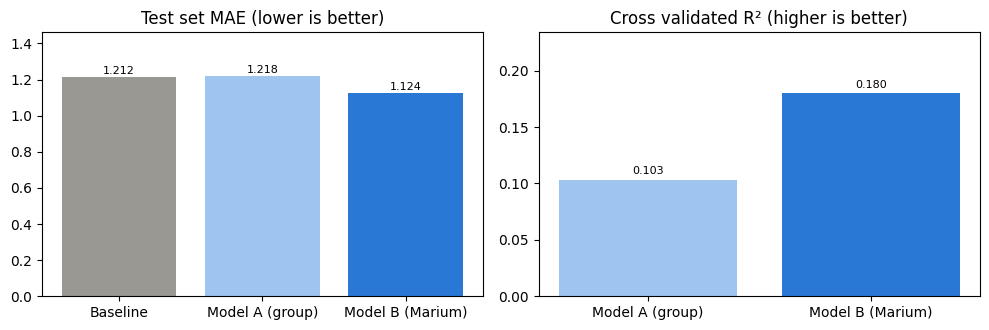

In [18]:
# chart 2: compare the models
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
names = ["Baseline", "Model A (group)", "Model B (Marium)"]
mae_values = [test_table.loc["Baseline (average)", "MAE"],
              test_table.loc["Model A (group)", "MAE"],
              test_table.loc["Model B (Marium)", "MAE"]]
ax[0].bar(names, mae_values, color=["#9a9893", "#9ec5f0", "#2a78d6"])
for i, v in enumerate(mae_values):
    ax[0].text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
ax[0].set_title("Test set MAE (lower is better)")
ax[0].set_ylim(0, max(mae_values) * 1.2)

r2_values = [cv_table.loc["Model A (group)", "CV R2"], cv_table.loc["Model B (Marium)", "CV R2"]]
ax[1].bar(["Model A (group)", "Model B (Marium)"], r2_values, color=["#9ec5f0", "#2a78d6"])
for i, v in enumerate(r2_values):
    ax[1].text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=8)
ax[1].set_title("Cross validated R² (higher is better)")
ax[1].set_ylim(0, max(r2_values) * 1.3)

plt.tight_layout()
plt.savefig("charts/chart2_model_comparison.png", dpi=200)
plt.show()

In [19]:
# final side by side comparison: Model A (group) vs Model B (Marium)
compare = pd.DataFrame({
    "Model A (group)": [test_table.loc["Model A (group)", "MAE"], test_table.loc["Model A (group)", "RMSE"],
                        test_table.loc["Model A (group)", "R2"], cv_table.loc["Model A (group)", "CV MAE"],
                        cv_table.loc["Model A (group)", "CV RMSE"], cv_table.loc["Model A (group)", "CV R2"]],
    "Model B (Marium)": [test_table.loc["Model B (Marium)", "MAE"], test_table.loc["Model B (Marium)", "RMSE"],
                         test_table.loc["Model B (Marium)", "R2"], cv_table.loc["Model B (Marium)", "CV MAE"],
                         cv_table.loc["Model B (Marium)", "CV RMSE"], cv_table.loc["Model B (Marium)", "CV R2"]],
}, index=["Test MAE", "Test RMSE", "Test R2", "CV MAE", "CV RMSE", "CV R2"])

# for R2 higher is better, for the errors lower is better
higher_better = compare.index.str.contains("R2")
compare["Better model"] = np.where(
    (compare["Model B (Marium)"] > compare["Model A (group)"]) == higher_better, "Model B (Marium)", "Model A (group)")
compare

,Model A (group),Model B (Marium),Better model
Test MAE,1.218,1.124,Model B (Marium)
Test RMSE,1.540,1.456,Model B (Marium)
Test R2,-0.078,0.037,Model B (Marium)
CV MAE,1.003,0.958,Model B (Marium)
CV RMSE,1.316,1.259,Model B (Marium)
CV R2,0.103,0.180,Model B (Marium)


## 6. Final model: Model B (Marium) on all 208 rows

In [20]:
final = sm.OLS(y, sm.add_constant(df[my_vars])).fit()
print(final.summary())

                            OLS Regression Results                            
Dep. Variable:           Goals_Scored   R-squared:                       0.279
Model:                            OLS   Adj. R-squared:                  0.250
Method:                 Least Squares   F-statistic:                     9.624
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           3.01e-11
Time:                        07:06:33   Log-Likelihood:                -329.63
No. Observations:                 208   AIC:                             677.3
Df Residuals:                     199   BIC:                             707.3
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     3.40

In [21]:
coef = pd.DataFrame({"coefficient": final.params, "p_value": final.pvalues}).drop("const").round(4)
coef

,coefficient,p_value
Opponent_FIFA_Ranking,0.0189,0.0000
Average_Goals_Scored,0.1074,0.5463
Average_Age,-0.1222,0.1469
Transfers_2025,-0.0002,0.8533
Coach_Salary_EUR,0.0000,0.4853
FIFA_Ranking_Apr2026,-0.0103,0.0664
Forward_Goal_Rate,3.0877,0.0307
Squad_Goals,0.0003,0.9129


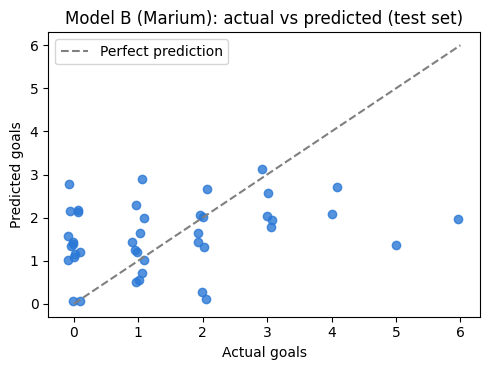

In [22]:
# chart 3: actual vs predicted goals on the test set (Model B)
fig, ax = plt.subplots(figsize=(5, 3.8))
jitter = np.random.default_rng(1).uniform(-0.1, 0.1, len(y_test))
ax.scatter(y_test + jitter, pred_b, color="#2a78d6", alpha=0.8)
ax.plot([0, 6], [0, 6], linestyle="--", color="grey", label="Perfect prediction")
ax.set_xlabel("Actual goals")
ax.set_ylabel("Predicted goals")
ax.set_title("Model B (Marium): actual vs predicted (test set)")
ax.legend()
plt.tight_layout()
plt.savefig("charts/chart3_actual_vs_predicted.png", dpi=200)
plt.show()

## 7. Summary

* The data had no missing values or duplicates. Three Panama rows had a negative xG, which I set to 0.
* The original 8 variables only describe the team itself, so the model could not tell an easy match from a hard one.
* My change: replace Team_xG (which repeats Average_Goals_Scored) with the **opponent's FIFA ranking**. It is known before the match and still gives exactly 8 variables.
* Model B (Marium) is better than Model A (group) and the baseline on every measure. The comparison table above shows the exact numbers.
* Football still has a lot of luck, so the typical error stays around one goal.